### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DOFM = data.copy()
DOFM = DOFM[DOFM['category']=='oil and fats']
DOFM.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
15,1/15/2008,Rakhine,Maungdaw,Alel Than Kyaw,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,2000.0,1.1236
18,1/15/2008,Rakhine,Maungdaw,Buthidaung,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,2000.0,1.1236
21,1/15/2008,Rakhine,Maungdaw,Kyein Chung,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,2000.0,1.1236
24,1/15/2008,Rakhine,Maungdaw,Maungdaw,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,1950.0,1.0955
27,1/15/2008,Rakhine,Maungdaw,Myin Hlut,oil and fats,Oil (palm),palm,NaN,L,actual,Retail,MMK,1600.0,0.8989


In [12]:
DOFM = DOFM[['date', 'price']]
DOFM['date'] = pd.to_datetime(DOFM['date'])
mask = (DOFM['date']>=obv_st_date) & (DOFM['date']<=obv_end_date)
DOFM = DOFM.loc[mask]
DOFM = DOFM.set_index('date')
DOFM.head()

,price
date,
2008-01-15,2000.0
2008-01-15,2000.0
2008-01-15,2000.0
2008-01-15,1950.0
2008-01-15,1600.0


In [13]:
DOFM = DOFM.resample('MS').mean()
DOFM.head()

,price
date,
2008-01-01,1979.836923
2008-02-01,2197.552308
2008-03-01,2211.887692
2008-04-01,2084.195385
2008-05-01,2173.426154


In [14]:
DOFM.shape

(169, 1)

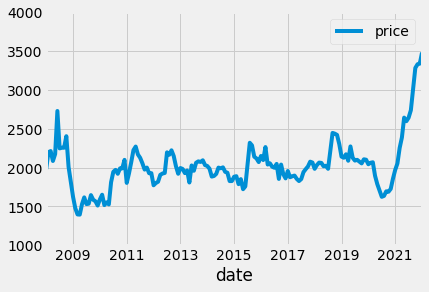

In [15]:
DOFM.plot(grid=True)
plt.show()

It has no trend.

##### Checking Random Walk

In [16]:
RW_DOFM= adfuller(DOFM)
RW_DOFM[1] # print P-value. If p-value<5%, reject null hypothesis

0.8963400382380142

<span style="color:red">Are there any external factors that may influence this price?</span>

##### Plotting ACF and PACF

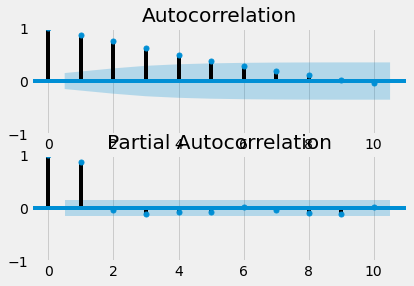

In [17]:
fig, axes=plt.subplots(2,1)
plot_acf(DOFM, lags=10, ax=axes[0])
plot_pacf(DOFM, lags=10, ax=axes[1])
plt.show()

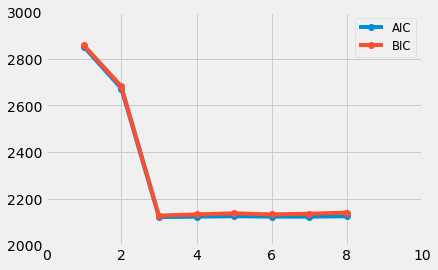

In [18]:
AIC, BIC = AIC_BIC_withOrderRange(DOFM, p=3, q=3)
# 0:(0,0,0), 1:(0,0,1), 2:(0,0,2), 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [19]:
AIC, BIC

(array([3059.13987714, 2851.67076633, 2672.07997201, 2121.04668664,
        2123.04049416, 2124.54091565, 2123.0397255 , 2122.85265558,
        2124.55294535]),
 array([3062.26977585, 2857.93056376, 2681.46966816, 2127.30648407,
        2132.43019031, 2137.06051051, 2132.42942164, 2135.37225044,
        2140.20243893]))

We will run again 3:(1,0,0), 4:(1,0,1), 5:(1,0,2), 6:(2,0,0), 7:(2,0,1), 8:(2,0,2)

In [20]:
mod_orders = [
    (1,0,0),
    (1,0,1),
    (1,0,2),
    (2,0,0),
    (2,0,1),
    (2,0,2)
]

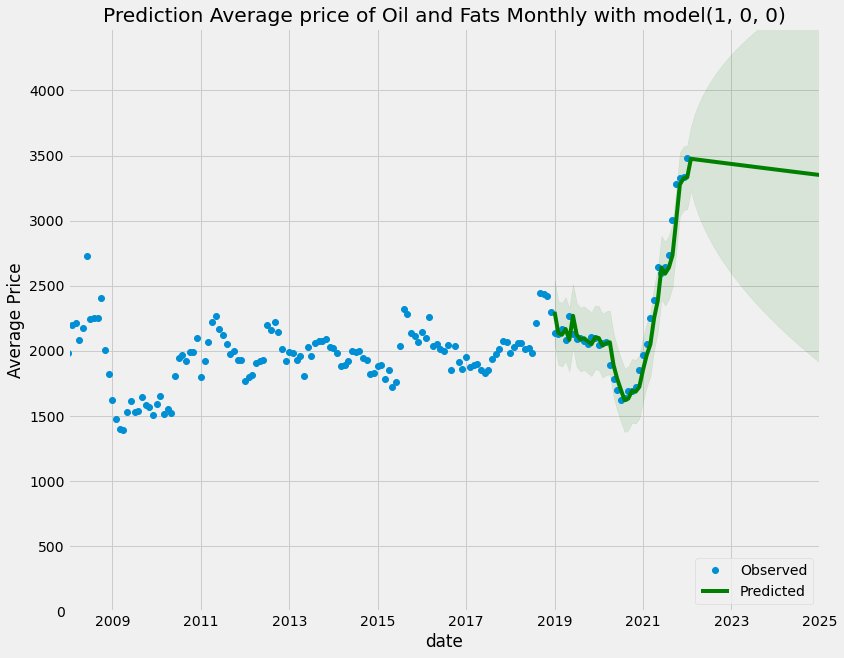

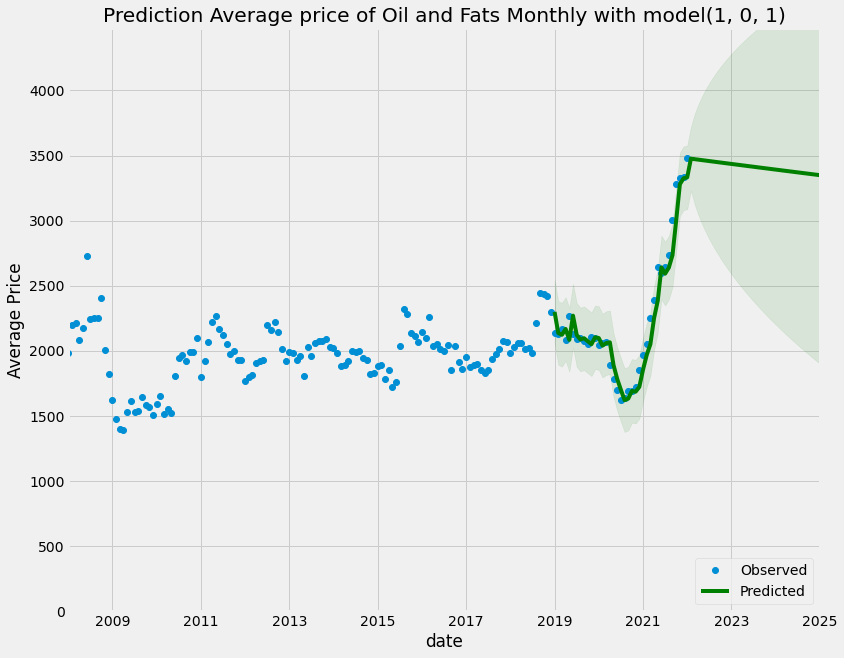

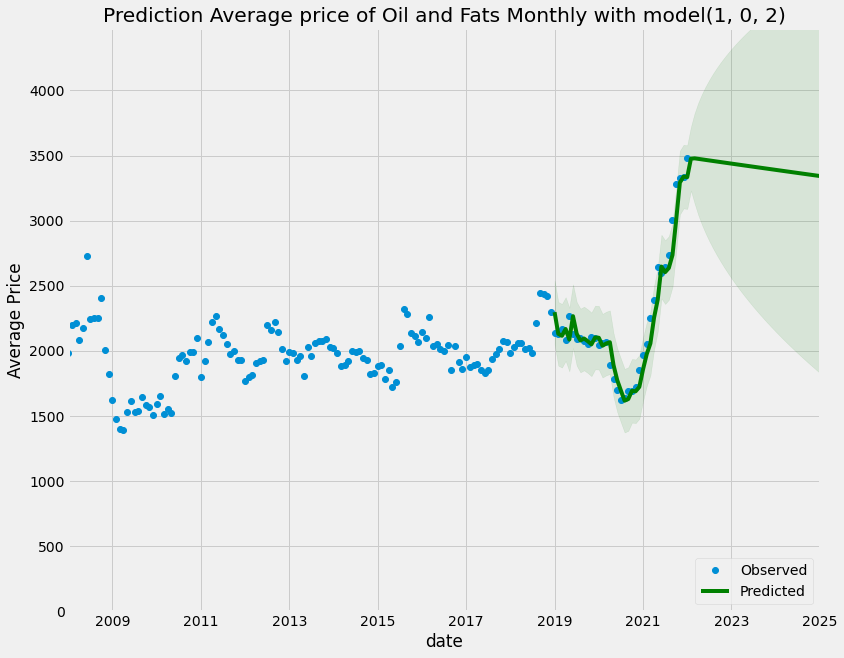

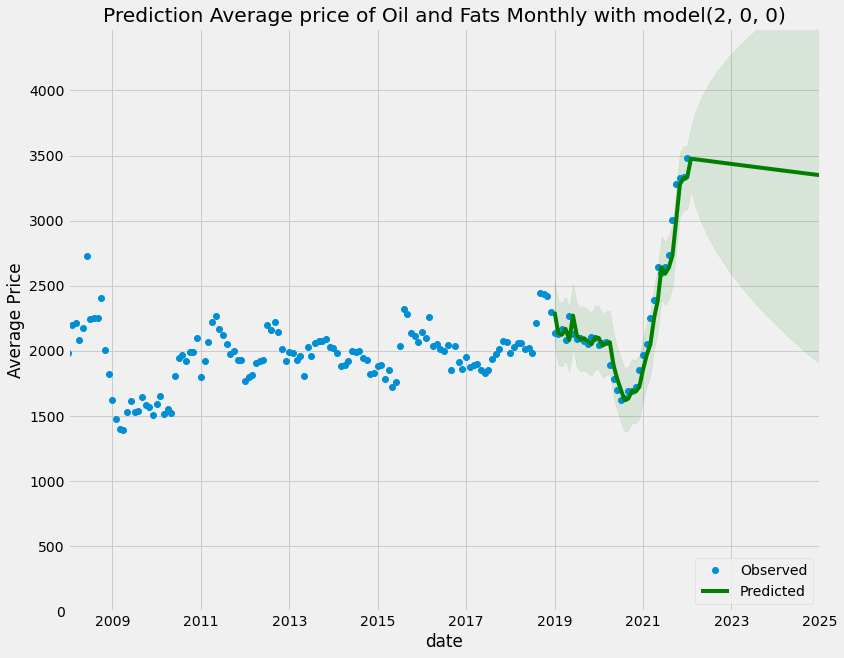

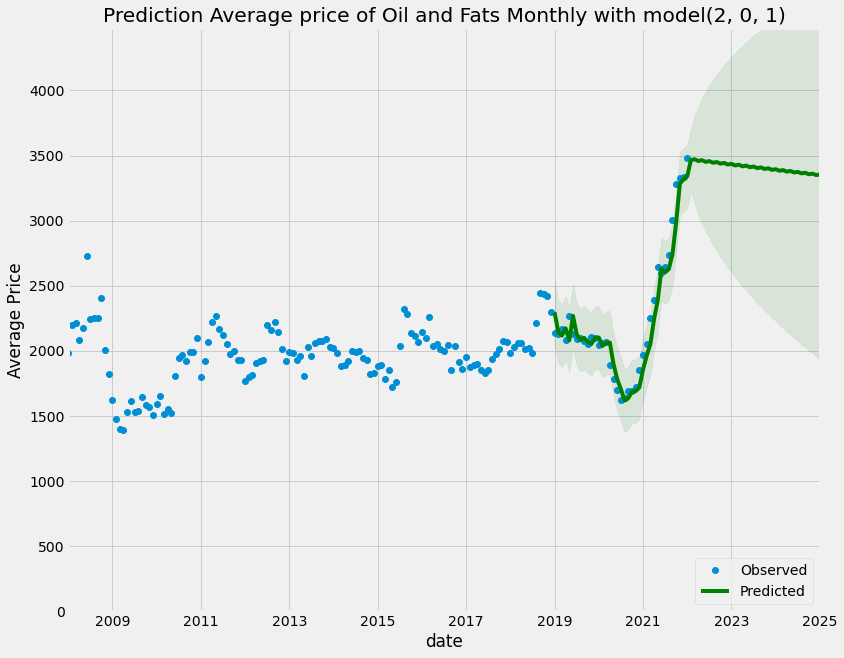

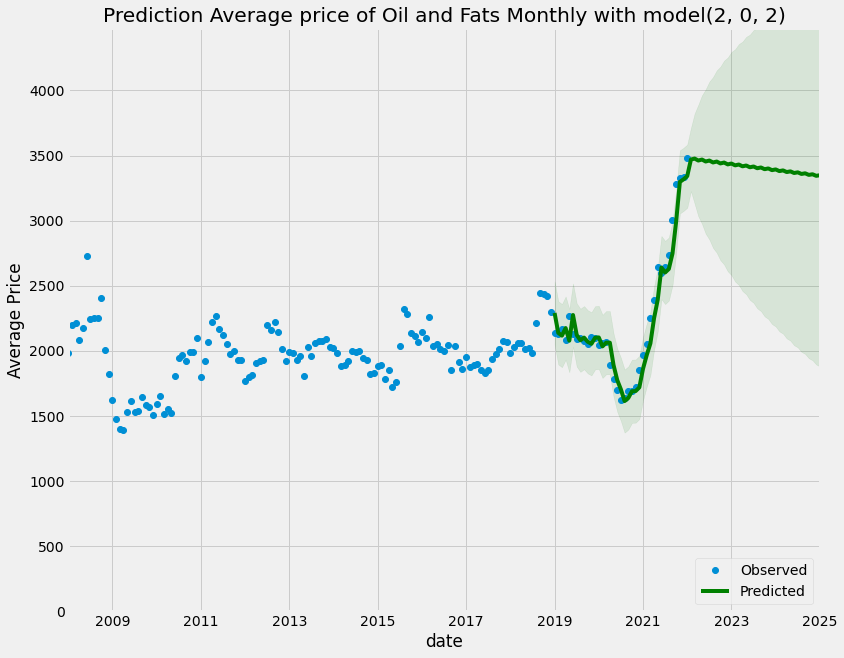

In [21]:
DOFM_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DOFM, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Oil and Fats Monthly with model'+str(order), xlabel='Date', ylabel='Average Price')
    DOFM_models.append(model)

Now we choose (1,0,0)

In [22]:
DOFM_model = DOFM_models[0]

In [23]:
DOFM_pred = DOFM_model.predict(pred_st_date, pred_end_date)
DOFM_pred

2019-01-01    2299.440195
2019-02-01    2138.100938
2019-03-01    2123.931115
2019-04-01    2168.038145
2019-05-01    2084.960481
                 ...     
2024-09-01    3364.475551
2024-10-01    3360.966761
2024-11-01    3357.461632
2024-12-01    3353.960157
2025-01-01    3350.462334
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64